In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
import os
os.chdir('E:/Machine_Learning/Datasets/')

In [2]:
df = pd.read_csv('monthly-milk-production-pounds-p.csv')
df

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


In [3]:
y = df['Milk']

----
# Moving Averages
----

### Centered Rolling Mean

In [4]:
span = 3
fcast= y.rolling(span,center=True).mean()
fcast

0             NaN
1      596.666667
2      619.000000
3      674.333333
4      693.333333
          ...    
163    857.000000
164    834.000000
165    813.666667
166    822.333333
167           NaN
Name: Milk, Length: 168, dtype: float64

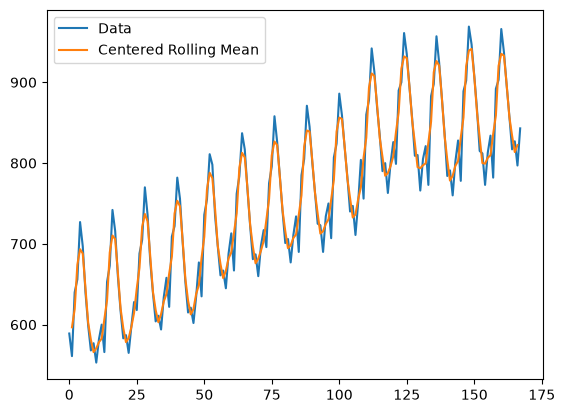

In [5]:
plt.plot(y,label = 'Data')
plt.plot(fcast,label = 'Centered Rolling Mean')
plt.legend(loc = 'best')
plt.show()

# Trailing Rolling Mean

In [6]:
y_train = df['Milk'][:-12]
y_test = df['Milk'][-12:]
y_train.shape,y_test.shape

((156,), (12,))

In [7]:
span = 5
fcast = y_train.rolling(window = span).mean()
MA = fcast.iloc[-1]
MA_Series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast , MA_Series] , ignore_index=True) # moving average forecast

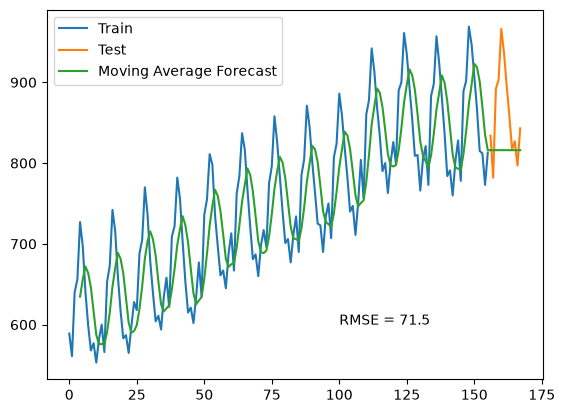

In [8]:
plt.plot(y_train , label = 'Train')
plt.plot(y_test , label = 'Test')
plt.plot(MA_fcast , label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test , MA_Series) , 2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

----
## Simple Exponential smoothing
----

In [9]:
from statsmodels.tsa.api import SimpleExpSmoothing

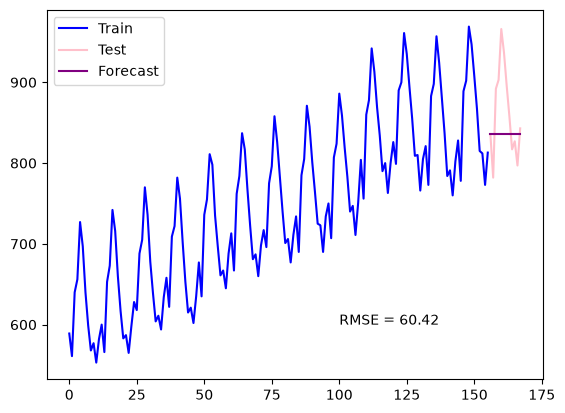

In [23]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train, initialization_method='estimated')
fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


----
# Holt’s method
----

### Holt's Linear Trend (Additive):

In [11]:
from statsmodels.tsa.api import Holt

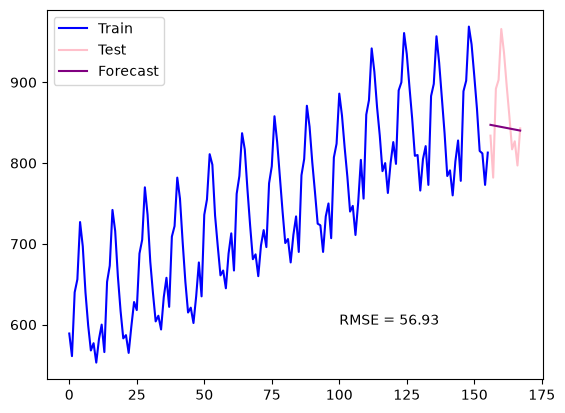

In [12]:
alpha,beta = 0.1,0.2
holt  = Holt(y_train, initialization_method='estimated')
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


### Holt's Exponential Trend (Multiplicative):

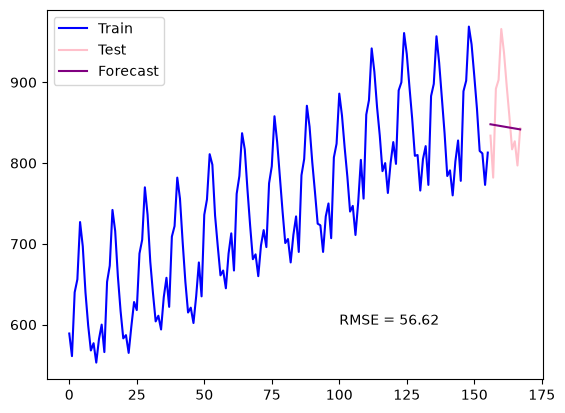

In [13]:
alpha,beta = 0.1,0.2
holt  = Holt(y_train, initialization_method='estimated',exponential=True) # just write exponential = True
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


### damped trend (Holt's)

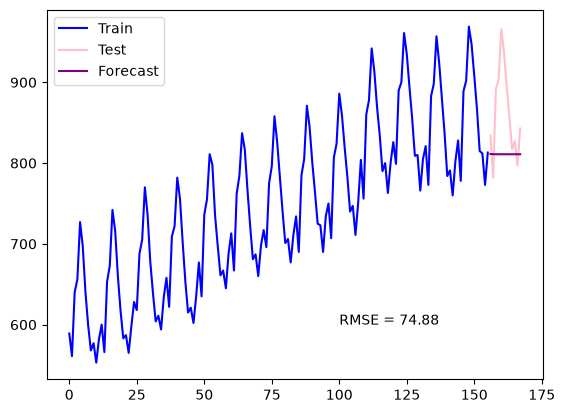

In [14]:
alpha,beta ,phi= 0.4,0.2,0.3
holt  = Holt(y_train, initialization_method='estimated',damped_trend=True) 
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


## Damped Exponential (Holt's)

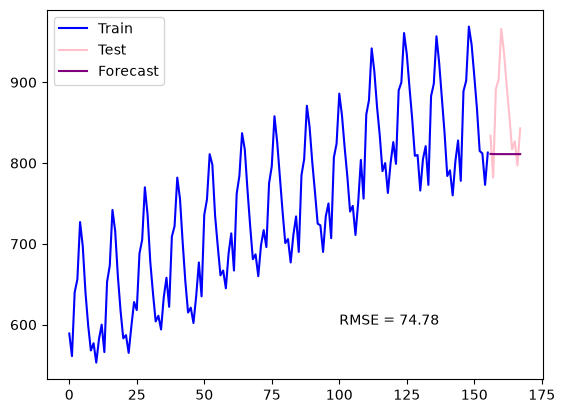

In [15]:
alpha,beta ,phi= 0.4,0.2,0.3
holt  = Holt(y_train, initialization_method='estimated',damped_trend=True,exponential=True) 
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


## Holt's Seasonal Exponential

In [16]:
from statsmodels.tsa.api import ExponentialSmoothing

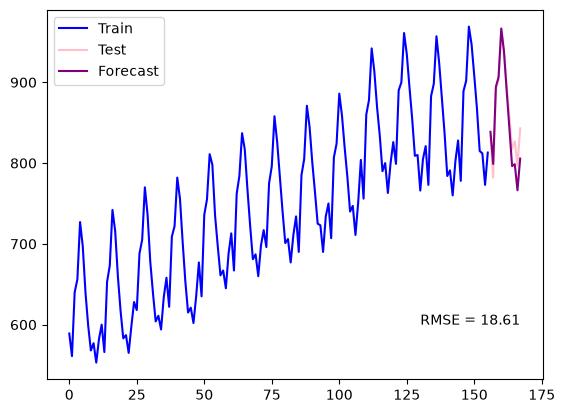

In [17]:
alpha,beta ,gamma= 0.6,0.2,0.1

hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend = 'add',seasonal = 'add')
fit1 = hw_add.fit(smoothing_level = alpha ,smoothing_trend = beta ,smoothing_seasonal = gamma)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(130,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


#### Automatic optimization

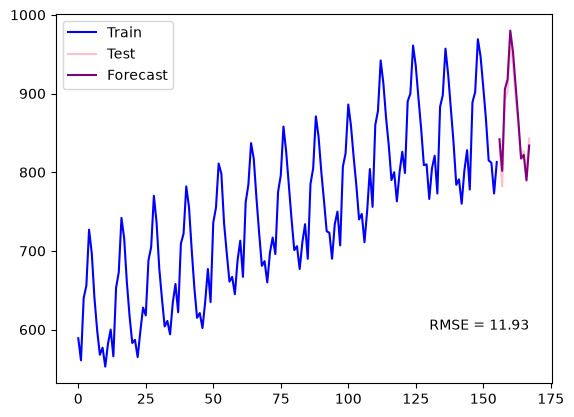

In [18]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend = 'add',seasonal = 'add')
fit1 = hw_add.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(130,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


In [19]:
fit1.params

{'smoothing_level': np.float64(0.6987277839956092),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(0.21200419486948743),
 'damping_trend': nan,
 'initial_level': np.float64(607.5085769889671),
 'initial_trend': np.float64(1.6172799752354758),
 'initial_seasons': array([-20.2658904 , -49.42286083,  34.92645658,  49.32892343,
        114.41858881,  87.94052914,  30.32471608, -17.58477658,
        -58.15958616, -55.32877891, -78.77980315, -44.01281414]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

In [20]:
from tqdm import tqdm

In [21]:
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)
gamma = np.linspace(0.01,0.99,10)
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend = 'add',seasonal = 'add')
            fit1 = hw_add.fit(smoothing_level = a ,smoothing_trend = b ,smoothing_seasonal = g)
            fcast1 = fit1.forecast(len(y_test))
            scores.append([a,b,g,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['alpha','beta','gamma','score'])
df_scores.sort_values('score',ascending=True)

 60%|██████    | 6/10 [00:43<00:33,  8.37s/it]C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
100%|██████████| 10/10 [01:34<00:00,  9.45s/it]


,alpha,beta,gamma,score
890,0.881111,0.990000,0.010000,8.115994
980,0.990000,0.881111,0.010000,8.618538
800,0.881111,0.010000,0.010000,8.886887
900,0.990000,0.010000,0.010000,8.915575
700,0.772222,0.010000,0.010000,8.996795
...,...,...,...,...
396,0.336667,0.990000,0.663333,87.049135
398,0.336667,0.990000,0.881111,88.955306
387,0.336667,0.881111,0.772222,90.501961
388,0.336667,0.881111,0.881111,93.589904
